# Calibration test

In [2]:
import spectre_analysis as sp_ana
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde
from typing import Dict, Union, Optional, Tuple, List

import datashader as ds
from datashader import transfer_functions as tf
import colorcet as cc

1) Extract data

In [3]:
spectrum_file = Path.cwd().parent / "data" / "standards" / "18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv"
spectrum = sp_ana.read_spectrum(spectrum_file)
spectrum.collect().head(5)

m/z,Intensity
f64,f64
500.514765,4984.59
500.515004,4699.41
500.515243,4163.71
500.515481,4129.75
500.51572,4831.31


In [4]:
workers = sp_ana.find_workers()
peaks = sp_ana.extract_and_detect_peaks(
    spectrum_data=spectrum,
    window=500,
    dist_min=0,
    prominence=3e5,
    n_workers=workers
)

In [7]:
monomers_list = ["dHex", "Hex", "HexA", "HexN", "HexNac", "Pent", "Neu", "NeuAc", "NeuGc"]
library = Path.cwd().parent / "data" / "oligo_combinations_clean.csv"
oligo_ref_all = sp_ana.adjust_library(library, monomers_list)
# Transform the mass in ppm and int to optimize the algorithm
for adduct in ['labeled_mass_H+', 'labeled_mass_Na+', 'labeled_mass_K+']:
    oligo_ref_all = sp_ana.normalize_mz_column(
    lf = oligo_ref_all,
    mz_col=adduct,
    new_col=f"{adduct}_int"
)

peaks = sp_ana.normalize_mz_column(
    lf = peaks,
    mz_col="m/z",
    new_col="mz_int"
)

In [8]:
peaks.collect()

m/z,Intensity,mz_int
f64,f64,i64
671.309344,2.850744e6,671309344
672.312899,907039.38,672312900
687.283794,6.183331e6,687283794
688.287873,1.6645e6,688287873
689.282669,322891.03,689282669
…,…,…
1489.73956,339598.09,1489739560
2489.131921,420384.56,2489131921
2776.256087,502445.66,2776256087


In [9]:
oligo_ref_all.collect()

column_id,dHex,Hex,HexA,HexN,HexNac,Pent,Neu,NeuAc,NeuGc,Neutral_unlabeled_mass,labeled_mass_H+,labeled_mass_Na+,labeled_mass_K+,labeled_mass_H+_int,labeled_mass_Na+_int,labeled_mass_K+_int
str,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,i64,i64,i64
"""0-0-0-0-0-1-0-0-0""",0,0,0,0,0,1,0,0,0,150.052825,277.118284,299.100229,315.074166,277118284,299100229,315074166
"""1-0-0-0-0-0-0-0-0""",1,0,0,0,0,0,0,0,0,164.068475,291.133934,313.115879,329.089816,291133934,313115879,329089816
"""0-0-0-1-0-0-0-0-0""",0,0,0,1,0,0,0,0,0,179.079374,306.144833,328.126778,344.100715,306144833,328126778,344100715
"""0-1-0-0-0-0-0-0-0""",0,1,0,0,0,0,0,0,0,180.06339,307.128849,329.110794,345.084731,307128849,329110794,345084731
"""0-0-1-0-0-0-0-0-0""",0,0,1,0,0,0,0,0,0,194.042655,321.108114,343.090059,359.063996,321108114,343090059,359063996
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""0-0-16-1-2-0-0-1-1""",0,0,16,1,2,0,0,1,1,3999.937315,4127.002774,4148.984719,4164.958656,4127002774,4148984719,4164958656
"""2-0-16-0-3-2-0-0-0""",2,0,16,0,3,2,0,0,0,3999.962467,4127.027926,4149.009871,4164.983808,4127027926,4149009871,4164983808
"""1-0-16-2-2-0-0-1-0""",1,0,16,2,2,0,0,1,0,3999.9737,4127.039159,4149.021104,4164.995041,4127039159,4149021104,4164995041


2. Map Différence Mass

Attention it is *O*(mxn) algo

In [48]:
def build_mass_difference_map(
    peaks: pl.LazyFrame,
    oligo_ref: pl.LazyFrame,
    adducts: List[str] = ['labeled_mass_H+', 'labeled_mass_Na+', 'labeled_mass_K+'],
    threshold_ppm: float = 500.0
) -> pl.LazyFrame:
    """
    Build a Mass Difference Map (MDiM) by computing delta_m (ppm) between experimental peaks
    and theoretical oligomers for each adduct.

    Args:
        peaks: LazyFrame containing experimental peaks with 'mz_int' column (integer m/z * 1e6).
        oligo_ref: LazyFrame containing theoretical oligomers with adduct mass columns.
        adducts: List of adduct columns to process (default: H+, Na+, K+).
        threshold_ppm: Mass tolerance in ppm (default: 50.0).


    Returns:
        pl.LazyFrame: Concatenated MDiM with columns:
            - All original columns from peaks
            - theoretical_mass (from oligo_ref)
            - delta_m (mass difference in ppm)
            - adduct (adduct type)

    Note:
        - Uses cross join (filtered in subsequent steps)
        - Avoids .collect() until final concatenation
        - Follows your preference for '_int' suffix and explicit typing
    """
    mdim_list = []
    for adduct in adducts:
        adduct_int = f"{adduct}_int"
        mdim = (
            peaks
            .join(
                oligo_ref.select(pl.col(adduct_int).alias("theoretical_mass")),
                how="cross")
            .with_columns(
                delta_m = (
                    (pl.col("mz_int") - pl.col("theoretical_mass")) / pl.col("theoretical_mass") * 1e6)
                    .alias("delta_m"))
            .filter(pl.col("delta_m").abs() <= threshold_ppm)
        )
        mdim_list.append(mdim)

    return pl.concat(mdim_list) if mdim_list else peaks.lazy().limit(0)

In [53]:
mdim_all_mono = build_mass_difference_map(peaks, oligo_ref_all)
mdim_all_mono.collect()

m/z,Intensity,mz_int,theoretical_mass,delta_m
f64,f64,i64,i64,f64
671.309344,2.850744e6,671309344,671277032,48.135119
672.312899,907039.38,672312900,672261048,77.130752
687.283794,6.183331e6,687283794,687260714,33.582598
687.283794,6.183331e6,687283794,687271947,17.237718
688.287873,1.6645e6,688287873,688255963,46.363565
…,…,…,…,…
3624.707599,468852.94,3624707599,3626413293,-470.352898
3624.707599,468852.94,3624707599,3626415979,-471.093225
3624.707599,468852.94,3624707599,3626423190,-473.080749


In [51]:
def plot_datashader_mdim(
    df: pl.DataFrame,
    x_col: str = "theoretical_mass",
    y_col: str = "delta_m",
    width: int = 800,
    height: int = 500
) -> None:
    """
    Trace une MDiM avec Datashader (pour gros datasets).
    Args:
        df: DataFrame Polars avec colonnes x_col et y_col.
        x_col: Nom de la colonne pour l'axe X.
        y_col: Nom de la colonne pour l'axe Y.
    Returns:
        Objet Holoviews pour affichage interactif.
    """
    # Conversion Polars → Pandas
    pdf = (df
        .select([(pl.col(x_col) / 1e6).alias("x_plot"),
            pl.col(y_col)])
        .drop_nulls()
        .to_pandas()
    )

    x_min, x_max = pdf["x_plot"].min(), pdf["x_plot"].max()
    y_min, y_max = pdf[y_col].min(), pdf[y_col].max()

    # Canvas Datashader
    canvas = ds.Canvas(
        plot_width=width,
        plot_height=height,
        x_range=(x_min, x_max),
        y_range=(y_min, y_max)
    )

    # Agrégation des points (compter par pixel)
    agg = canvas.points(pdf, "x_plot", y_col, agg=ds.count())
    

    # Appliquer une colormap (échelle logarithmique)
    img = tf.shade(agg, cmap=cc.fire, how='log')
    img = tf.set_background(img, "white")

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.imshow(
        img.to_pil(),
        extent=[x_min, x_max, y_min, y_max],
        aspect="auto"
    )

    ax.set_xlabel("References mass (Da)")
    ax.set_ylabel("Delta mass (ppm)")


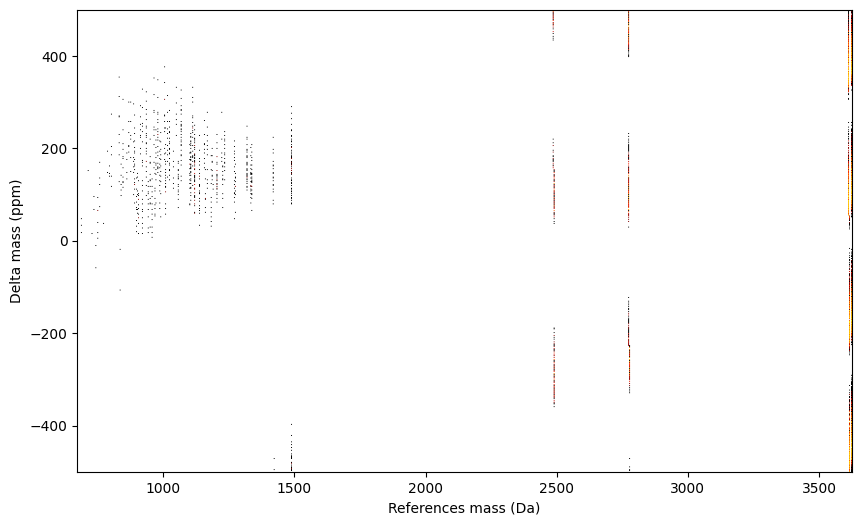

In [54]:
mdim_all_mono = mdim_all_mono.collect()
plot_datashader_mdim(mdim_all_mono)

In [12]:
monomers_list = ["Hex", "Pent"]
library = Path.cwd().parent / "data" / "oligo_combinations_clean.csv"
oligo_ref_selection = sp_ana.adjust_library(library, monomers_list)
# Transform the mass in ppm and int to optimize the algorithm
for adduct in ['labeled_mass_H+', 'labeled_mass_Na+', 'labeled_mass_K+']:
    oligo_ref_selection = sp_ana.normalize_mz_column(
    lf = oligo_ref_selection,
    mz_col=adduct,
    new_col=f"{adduct}_int"
)

In [13]:
oligo_ref_selection.collect()

column_id,Hex,Pent,Neutral_unlabeled_mass,labeled_mass_H+,labeled_mass_Na+,labeled_mass_K+,labeled_mass_H+_int,labeled_mass_Na+_int,labeled_mass_K+_int
str,i64,i64,f64,f64,f64,f64,i64,i64,i64
"""0-0-0-0-0-1-0-0-0""",0,1,150.052825,277.118284,299.100229,315.074166,277118284,299100229,315074166
"""0-1-0-0-0-0-0-0-0""",1,0,180.06339,307.128849,329.110794,345.084731,307128849,329110794,345084731
"""0-0-0-0-0-2-0-0-0""",0,2,282.095085,409.160544,431.142489,447.116426,409160544,431142489,447116426
"""0-1-0-0-0-1-0-0-0""",1,1,312.10565,439.171109,461.153054,477.126991,439171109,461153054,477126991
"""0-2-0-0-0-0-0-0-0""",2,0,342.116215,469.181674,491.163619,507.137556,469181674,491163619,507137556
…,…,…,…,…,…,…,…,…,…
"""0-23-0-0-0-1-0-0-0""",23,1,3877.2678,4004.333259,4026.315204,4042.289141,4004333259,4026315204,4042289141
"""0-24-0-0-0-0-0-0-0""",24,0,3907.278365,4034.343824,4056.325769,4072.299706,4034343824,4056325769,4072299706
"""0-20-0-0-0-5-0-0-0""",20,5,3919.278365,4046.343824,4068.325769,4084.299706,4046343824,4068325769,4084299706


In [16]:
mdim_selection_mono = build_mass_difference_map(peaks, oligo_ref_selection)
mdim_selection_mono.collect()

m/z,Intensity,mz_int,theoretical_mass,delta_m
f64,f64,i64,i64,f64
671.309344,2.850744e6,671309344,277118284,1.4225e6
671.309344,2.850744e6,671309344,307128849,1.1858e6
671.309344,2.850744e6,671309344,409160544,640699.118828
671.309344,2.850744e6,671309344,439171109,528582.664576
671.309344,2.850744e6,671309344,469181674,430808.962074
…,…,…,…,…
3624.707599,468852.94,3624707599,4042289141,-103303.23424
3624.707599,468852.94,3624707599,4072299706,-109911.386517
3624.707599,468852.94,3624707599,4084299706,-112526.538228


NOTE ==> No threshold for the graph below

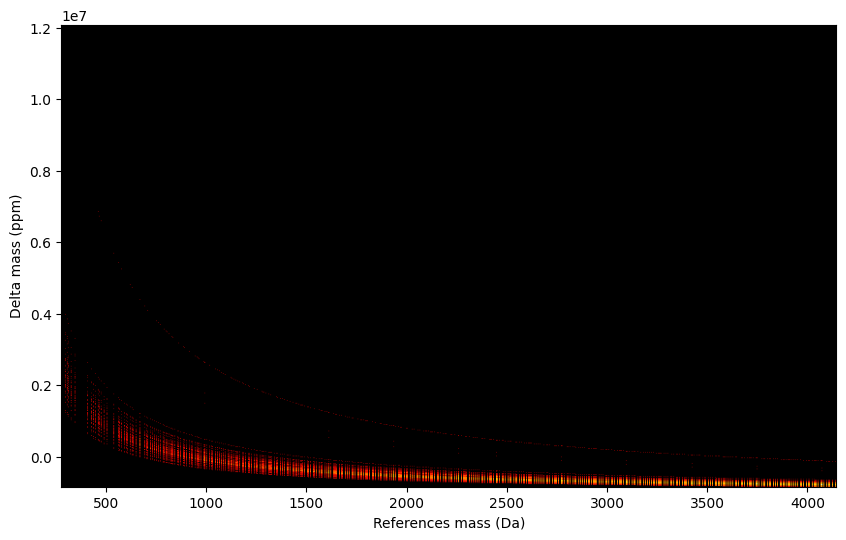

In [17]:
mdim_selection_mono = mdim_selection_mono.collect()
plot_datashader_mdim(mdim_selection_mono)

3. KDE evaluation

In [17]:
def calculate_kde(
    x: np.ndarray,
    y: np.ndarray,
    bandwidth: float = 0.5
) -> np.ndarray:
    """
    Calcule la densité KDE pour une MDiM.
    Args:
        x: Masses théoriques (theoretical_mass).
        y: Différences de masse (delta_m).
        bandwidth: Paramètre de lissage (ajuste selon la résolution).
    Returns:
        Tableau de densités (même taille que x/y).
    """
    # Empiler les coordonnées
    xy = np.vstack([x, y])

    # Calculer la KDE
    kde = gaussian_kde(xy, bw_method=bandwidth)
    return kde(xy)

In [ ]:
x = mdim_all_mono["theoretical_mass"].to_numpy() / 10e6
y = mdim_all_mono["delta_m"].to_numpy()
try:
    densities = calculate_kde(x, y)
except Exception as e:
    print(f"Erreur dans calculate_kde : {e}")

In [22]:
def plot_kde_mdim(
    x: np.ndarray,
    y: np.ndarray,
    densities: np.ndarray,
    figsize: tuple = (10, 6)
) -> plt.Figure:
    """
    Trace la MDiM avec la KDE en couleur.
    Args:
        x: Masses théoriques.
        y: Différences de masse.
        densities: Densités calculées par KDE.
    Returns:
        Figure Matplotlib.
    """
    fig, ax = plt.subplots(figsize=figsize, facecolor='none')

    # Scatter plot avec couleur basée sur la densité
    sc = ax.scatter(
        x, y,
        c=densities,
        s=2,
        alpha=0.5,
        cmap='viridis',
        edgecolors='none'
    )

    # Barre de couleur
    plt.colorbar(sc, label="Density")

    # Ligne rouge pour ΔM = 0 ppm
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1, label="ΔM = 0 ppm")

    # Personnalisation
    ax.set_xlabel("Theoretical Mass (Da)", fontsize=12)
    ax.set_ylabel("Mass Difference (ppm)", fontsize=12)
    ax.set_title("MDiM with KDE Density", fontsize=14)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

    # Fond transparent
    fig.patch.set_alpha(0.0)
    return fig


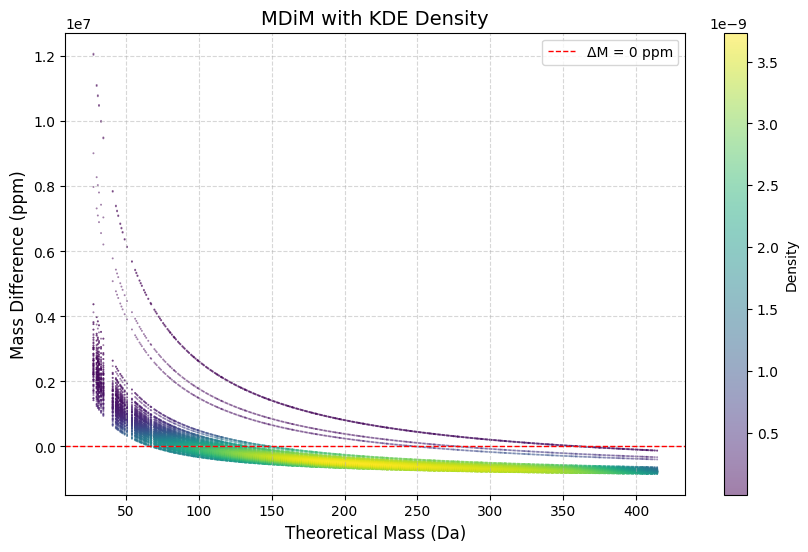

In [21]:

# Affichage
fig = plot_kde_mdim(x, y, densities)
plt.show()

4. Calibration of the mass

In [23]:
from scipy.signal import savgol_filter

In [ ]:
def fit_kernel(
    mdim_df: pl.LazyFrame,
    mass_col: str = "theoretical_mass",
    delta_col: str = "delta_m",
    err_ppm: float = 3.0,
    bandwidth: float = 0.5,
    show_map: bool = True,
    chunk_size: int = 100_000
) -> Tuple[pl.DataFrame, plt.Figure]:
    """
    Extract the recalibration curve from a Mass Difference Map using KDE ridge extraction.
    Optimized for large datasets (processes in chunks) and integrates with your Polars pipeline.

    Args:
        mdim_df: LazyFrame containing MDiM data (from build_mass_difference_map).
        mass_col: Column name for theoretical masses (default: "theoretical_mass").
        delta_col: Column name for mass differences (default: "delta_m").
        err_ppm: Error range in ppm for KDE grid (±err_ppm).
        bandwidth: KDE smoothing parameter.
        show_map: If True, returns a figure with KDE map and fitted curve.
        chunk_size: Number of points to process at once (memory management).

    Returns:
        Tuple[pl.DataFrame, plt.Figure]:
            - DataFrame with columns: ["mass", "ppm_error"] (recalibration curve)
            - Matplotlib Figure (if show_map=True, else None)

    Note:
        - Uses downsampling for large datasets (>1M points)
        - Applies Savitzky-Golay filtering for smoothing
    """
    # 1. Collect only the necessary columns (memory-efficient)
    df = mdim_df.select([mass_col, delta_col]).collect()

    # 2. Downsample if dataset is too large
    if len(df) > 1_000_000:
        df = df.sample(n=1_000_000, shuffle=True, seed=42)

    # 3. Convert to numpy arrays
    x = df[mass_col].to_numpy()
    y = df[delta_col].to_numpy()

    # 4. Calculate KDE on a grid
    x_grid = np.linspace(x.min(), x.max(), 1000)
    y_grid = np.linspace(-err_ppm, err_ppm, 1000)
    X, Y = np.meshgrid(x_grid, y_grid)
    positions = np.vstack([X.ravel(), Y.ravel()])

    # Calculate KDE values for grid points
    xy = np.vstack([x, y])
    kde = gaussian_kde(xy, bw_method=bandwidth)
    Z = kde(positions).reshape(X.shape)

    # 5. Extract ridge (max density for each x)
    ridge_ppm = np.argmax(Z, axis=0)
    ridge_y = y_grid[ridge_ppm]

    # 6. Smooth the ridge using Savitzky-Golay
    window_length = min(31, len(ridge_y) - 1)  # Ensure odd and < len(ridge_y)
    ppm_smoothed = savgol_filter(ridge_y, window_length, 3)

    # 7. Create output DataFrame
    result_df = pl.DataFrame({
        "mass": x_grid,
        "ppm_error": ppm_smoothed
    })

    # 8. Plot if requested
    fig = None
    if show_map:
        fig = plt.figure(figsize=(10, 6), facecolor='none')
        ax = fig.add_subplot(111)

        # Plot KDE map
        contour = ax.contourf(
            X, Y, Z,
            levels=20,
            cmap='viridis',
            alpha=0.8
        )
        plt.colorbar(contour, label="Density")

        # Plot ridge line
        ax.plot(x_grid, ppm_smoothed, color='red', linewidth=2, label="Recalibration curve")
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1)

        # Formatting (your preferred style)
        ax.set_xlabel("Theoretical Mass (Da)", fontsize=12)
        ax.set_ylabel("Mass Difference (ppm)", fontsize=12)
        ax.set_title("Mass Difference Map with KDE Ridge", fontsize=14)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend()
        fig.patch.set_alpha(0.0)  # Transparent background

    return result_df, fig

NOTE: The use of the KDE need a grid to explore non measure data point --> Not needed here --> Rolling Avergage maybe teh best solution 

| Method Comparison                     | KDE (with grid)                                      | Rolling Average (`rolling_mean`)                     |
|----------------------------------------|------------------------------------------------------|--------------------------------------------------|
| **Core Principle**                     | Estimates 2D probability density (mass × error) via Gaussian kernel | Locally smooths errors by calculating windowed averages |
| **Data Coverage**                      | Models all possible mass/error combinations          | Works only on measured masses                     |
| **Interpolation**                      | Interpolates errors even where no data exists        | Based solely on existing data points             |
| **Typical Code**                       | `gaussian_kde` + `meshgrid` + ridge extraction       | `.rolling_mean(window_size=50, min_periods=1)`   |
| **Complexity**                         | O(n²) (due to 1000×1000 grid)                        | **O(n)** (linear, optimized for Polars)          |
| **Memory Usage**                       | High (1M elements for 1000×1000 grid)                | Low (buffer size = `window_size`)                |
| **Precision**                          | Captures non-linear trends (e.g., curvatures)        | Local linear smoothing (ideal for slowly varying errors) |
| **Outlier Robustness**                 | Robust (Gaussian kernel)                             | Sensitive if `window_size` is too small          |
| **Key Parameters**                     | `bandwidth`, `err_ppm`, grid size                    | **`window_size`** (e.g., 50 for oligomers)       |
| **Output**                             | Continuous surface (heatmap + ridge)                 | Discrete curve (1 value per measured peak)       |
| **Integration**                        | Requires numpy↔Polars conversions                     | **100% compatible** with Polars/LazyFrame        |
| **Visualization**                      | Enables heatmaps (diagnostic)                        | Simple to plot (`plt.plot`)                      |


*Data from Lechat (Mistral)*

In [34]:
def calculate_error_table(
    mdim_df: pl.LazyFrame,
    mass_col: str = "theoretical_mass",
    delta_col: str = "delta_m",
    window_size: int = 100  # Nombre de masses voisines pour le lissage
) -> pl.LazyFrame:
    """
    Calcule la correction sans grille, en utilisant uniquement les masses mesurées.
    Args:
        mdim_df: Résultat de build_mass_difference_map (avec colonnes mass_col, delta_col)
        window_size: Taille de la fenêtre pour le lissage mobile (en nombre de masses)
    Returns:
        DataFrame avec colonnes: [mass_col, ppm_correction]
    """
    # 1. Trie par masse théorique et calcule une correction lissée
    return (
        mdim_df.lazy()
        .sort(mass_col) # Mandatory for rooling
        .with_columns(
            # Rolling Average
            pl.col(delta_col)
            .rolling_mean(window_size=window_size, min_samples=1)
            .alias("ppm_correction"))
        .select([mass_col, "ppm_correction"])
    )


In [55]:
error_table = calculate_error_table(mdim_all_mono)
error_table.collect()

theoretical_mass,ppm_correction
i64,f64
671277032,48.135119
672261048,62.632936
687260714,52.94949
687271947,44.021547
688255963,44.48995
…,…
3626494191,-469.687288
3626496877,-470.057468
3626505424,-470.45043


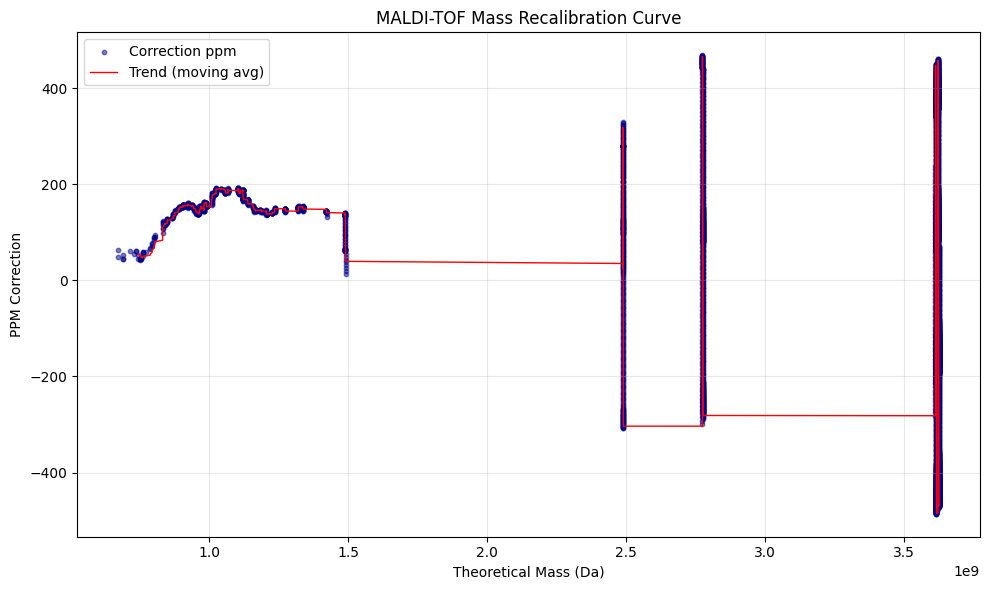

In [56]:
correction_data = error_table.collect()
plt.figure(figsize=(10, 6), facecolor='none')  # Fond transparent (Memory #3)
plt.scatter(
    correction_data["theoretical_mass"],
    correction_data["ppm_correction"],
    s=10,  # Taille des points (réduis si trop dense)
    alpha=0.5,
    color='darkblue',
    label='Correction ppm'
)

# Lissage visuel (optionnel : moyenne mobile sur les points tracés)
plt.plot(
    correction_data["theoretical_mass"],
    correction_data["ppm_correction"].rolling_mean(window_size=10),  # Lissage supplémentaire
    color='red',
    linewidth=1,
    label='Trend (moving avg)'
)

plt.xlabel("Theoretical Mass (Da)")
plt.ylabel("PPM Correction")
plt.title("MALDI-TOF Mass Recalibration Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Mass Correction Formula (ppm)

The corrected mass is calculated using the relative ppm formula:

$$
m_{\text{corrected}} = \frac{m_{\text{measured}}}{1 + \frac{\text{ppm}}{10^6}}
$$

**Where:**
- $m_{\text{measured}}$: Experimental mass (Da)
- $\text{ppm}$: Mass error in parts per million
- $m_{\text{corrected}}$: Recalibrated mass (Da)

In [ ]:
def apply_mass_correction(
    peaks: pl.LazyFrame,
    recalib_curve: pl.LazyFrame,
    mass_col: str = "m/z"
) -> pl.LazyFrame:
    """
    Applies ppm-based mass correction to MALDI-TOF spectra using the relative correction formula:

    $$
    m_{\text{corrected}} = \frac{m_{\text{measured}}}{1 + \frac{\text{ppm}}{10^6}}
    $$

    This method provides mathematically exact ppm correction across the entire mass range,
    unlike absolute subtraction which introduces mass-dependent residuals.

    Args:
        peaks: LazyFrame containing experimental peaks with a `mass_col` column (Da).
        recalib_curve: LazyFrame with correction values [mass_col, ppm_correction].
        mass_col: Name of mass column (default: "m/z").

    Returns:
        pl.LazyFrame: Original DataFrame with added 'corrected_mz' column (Da).
    """
    return (
        peaks.join(recalib_curve, on=mass_col, how="left")
        .with_columns(
            corrected_mz = pl.col(mass_col) / (1 + pl.col("ppm_correction").fill_null(0) / 1e6)
        )
    )

In [71]:
def interpolate_corrections(
    spectrum: pl.LazyFrame,  # TOUT le spectre (m/z + Intensity)
    recalib_curve: pl.LazyFrame,  # Pics assignés + ppm_correction
    experimental_mass_col: str = "mz_int",
    theorical_mass_col: str = "theoretical_mass"
) -> pl.LazyFrame:
    """
    Interpole les corrections ppm pour TOUTES les masses du spectre.
    Args:
        spectrum: Toutes les masses à corriger (même le bruit).
        recalib_curve: Pics assignés avec leur ppm_correction.
    Returns:
        LazyFrame avec une colonne `ppm_correction` interpolée pour toutes les masses.
    """
    # 1. Collecter les données (nécessaire pour numpy)
    spectrum = sp_ana.normalize_mz_column(
        lf = spectrum,
        mz_col="m/z",
        new_col="mz_int")
    masses = spectrum.select(experimental_mass_col).collect().to_numpy().ravel()
    known_masses = recalib_curve.select(pl.col(theorical_mass_col)).collect().to_numpy().ravel()
    known_corrections = recalib_curve.select(pl.col("ppm_correction")).collect().to_numpy().ravel()

    # ---- Sécurisation : tri obligatoire ----
    order = np.argsort(known_masses)
    known_masses = known_masses[order]
    known_corrections = known_corrections[order]

    # 2. Interpolation linéaire
    corrections_interp = np.interp(
        masses,  # Où interpoler (toutes les masses)
        known_masses,  # Masses connues (assignées)
        known_corrections  # Corrections connues
    )

    # 3. Ajouter les corrections interpolées au DataFrame
    return (spectrum
            .with_columns(ppm_correction=pl.lit(corrections_interp),
                          corrected_mz=pl.col(experimental_mass_col) / (1 + pl.lit(corrections_interp) / 1e6))
            .with_columns((pl.col("corrected_mz") / 1e6).alias("new_mz"))
            .select(["m/z","new_mz", 'Intensity'])
    )

In [72]:
# Utilisation
corrected_spectrum = interpolate_corrections(spectrum, error_table)

In [73]:
corrected_spectrum.collect()

m/z,new_mz,Intensity
f64,f64,f64
500.514765,500.490674,4984.59
500.515004,500.490913,4699.41
500.515243,500.491152,4163.71
500.515481,500.49139,4129.75
500.51572,500.491629,4831.31
…,…,…
3999.92301,4001.80896,27359.84
3999.938252,4001.824209,30764.9
3999.953495,4001.839459,38632.98


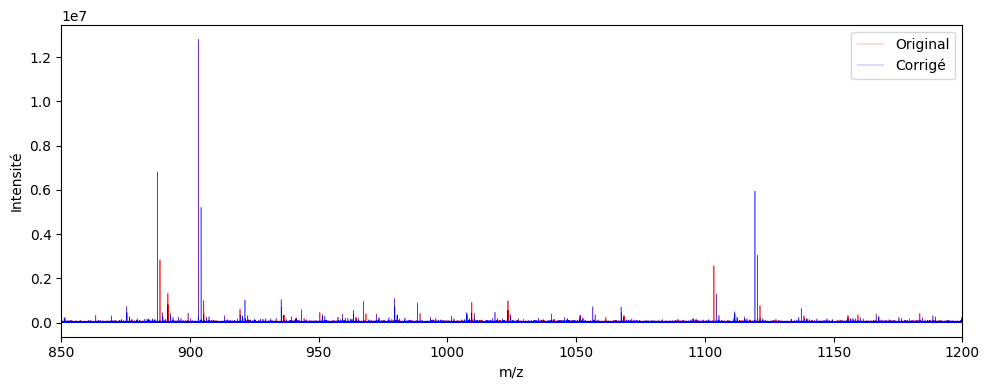

In [85]:
df = corrected_spectrum.collect()


plt.figure(figsize=(10, 4))

plt.plot(df["m/z"], df["Intensity"], label="Original", linewidth=0.2, color='red')
plt.plot(df["new_mz"], df["Intensity"], label="Corrigé", linewidth=0.2, color='blue')

plt.xlabel("m/z")
plt.ylabel("Intensité")
plt.xlim([850,1200])
plt.legend()
plt.tight_layout()
plt.show()